In [2]:
from kinetic_model.constants.energy_profile import EnergyBarriersSimplifyed, EnergyBarriers
from kinetic_model.simulation.run_reactor import ReactorSimulationChemisorptionSimplified, ReactorSimulationChemisorption
from kinetic_model.core.diffusion import Reaction_Diffusion
import seaborn as sns
import joblib
import numpy as np
import pandas as pd
import math
from copy import deepcopy
import re

from kinetic_model.simulation.reaction_list_creator import (
    make_reaction_list_chemisorp_simplified,
    prepare_constants_chemisorp_simplified
)


class ReactorStream(ReactorSimulationChemisorptionSimplified):
    """
    A class to handle the reactor stream simulation.
    Inherits from ReactorSimulationChemisorption.
    """
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)

    def _build_solver(self):
        df, idx = self._make_dataframe()
        self._diffusion_rates = self._calc_diffusion_constants(df, idx)
        self._capacity = self._calc_capacity(df, idx)

        for key, _ in self._capacity.items():
            if 'out' in key:
                self._capacity[key] = 1e6


        self.consts = prepare_constants_chemisorp_simplified(
            self.barrier_params,
            temperature=self.T
        )
        self._reactions = make_reaction_list_chemisorp_simplified(
            n_max=self.N,
            consts=self.consts,
            diffusion_rates=self._diffusion_rates,
            include_diffusion=self.include_diffusion

        )

        for i, reaction in enumerate(self._reactions):
            string = reaction[0].replace('<D>', 'D>')
            self._reactions[i] = (string, reaction[1], reaction[2], )

        return Reaction_Diffusion(reactions=self._reactions, capacity=self._capacity, 
                                  fixed_concentrations=['C2', 'C2_out'])


def time_distribution(result: pd.DataFrame) -> pd.DataFrame:
    """
    Compute per-time distribution P(C_n | n>2) from a wide time series.

    Input
    -----
    result : DataFrame with columns like:
        time, C2, C2_out, C4, C4_out, C6, C6_out, ...

    Output
    ------
    DataFrame with columns:
        time, n, probability   (only n > 2)

    Notes
    -----
    - Uses only in-reactor columns matching exactly 'C\\d+' (excludes '*_out').
    - If total concentration of n>2 at a time is 0, probabilities are NaN for that time.
    """
    if 'time' not in result.columns:
        raise ValueError("Input must contain a 'time' column.")

    # Keep only exact Cn columns (exclude *_out etc.)
    cn_cols = [c for c in result.columns if re.fullmatch(r'C\d+', c)]

    if not cn_cols:
        return pd.DataFrame(columns=['time', 'n', 'probability'])

    # Wide -> long
    long = (result[['time'] + cn_cols]
            .melt(id_vars='time', var_name='species', value_name='concentration'))

    # Extract n
    long['n'] = long['species'].str.extract(r'(\d+)').astype(int)

    # Totals per time over n>2
    totals = (long.loc[long['n'] > 2]
                    .groupby('time', as_index=False)['concentration']
                    .sum()
                    .rename(columns={'concentration': 'total_conc'}))

    # Merge totals, compute probabilities, filter n>2
    out = (long.merge(totals, on='time', how='left')
                .assign(probability=lambda d: d['concentration'] / d['total_conc'])
                .loc[lambda d: d['n'] > 2, ['time', 'n', 'probability']]
                .sort_values(['time', 'n'])
                .reset_index(drop=True))

    return out


def tail_slope_prob_per_n(dist: pd.DataFrame, tail_frac: float = 0.10) -> pd.DataFrame:
    """
    Compute d(probability)/dt for each n over the last `tail_frac` of the simulation time.

    Parameters
    ----------
    dist : pd.DataFrame
        Long-form dataframe with columns: ['time', 'n', 'probability'].
    tail_frac : float, optional (default=0.10)
        Fraction of the *time span* to use from the end (e.g., 0.10 = last 10%).

    Returns
    -------
    pd.DataFrame with columns:
        - n : int
        - slope : float  (units: probability per time)
        - window_start : float  (time at which the tail window starts)
        - window_end : float    (max time)
        - points_used : int     (# of points used in the fit for that n)

    Notes
    -----
    - Uses np.polyfit on (time, probability) within the tail window, after dropping NaNs.
    - If fewer than 2 points for an n in the tail window, slope is NaN.
    """
    required_cols = {'time', 'n', 'probability'}
    missing = required_cols - set(dist.columns)
    if missing:
        raise ValueError(f"Input distribution is missing columns: {missing}")

    # Ensure proper dtypes
    d = dist[['time', 'n', 'probability']].copy()
    d['time'] = pd.to_numeric(d['time'], errors='coerce')
    d['n'] = pd.to_numeric(d['n'], errors='coerce', downcast='integer')
    d['probability'] = pd.to_numeric(d['probability'], errors='coerce')

    # Determine tail time window using the overall time span
    t_min = d['time'].min()
    t_max = d['time'].max()
    if not np.isfinite(t_min) or not np.isfinite(t_max):
        return pd.DataFrame(columns=['n', 'slope', 'window_start', 'window_end', 'points_used'])

    window_start = t_min + (1 - tail_frac) * (t_max - t_min)
    tail = d[(d['time'] >= window_start) & (d['time'] <= t_max)]

    results = []
    for n_val, g in tail.groupby('n', dropna=True):
        g = g.dropna(subset=['time', 'probability']).sort_values('time')
        if len(g) < 2:
            slope = np.nan
            points_used = len(g)
        else:
            # Linear fit: probability ~ a*time + b; slope = a
            a, b = np.polyfit(g['time'].values, g['probability'].values, deg=1)
            slope = float(a)
            points_used = len(g)

        results.append({
            'n': int(n_val) if pd.notna(n_val) else np.nan,
            'slope': slope,
            'window_start': float(window_start),
            'window_end': float(t_max),
            'points_used': int(points_used),
        })

    return pd.DataFrame(results).sort_values('n').reset_index(drop=True)


def check_convergance(ts, error_threshold=1e-2):
    distr = time_distribution(ts.reset_index(names=['time']))
    is_converged = bool(tail_slope_prob_per_n(distr, tail_frac=0.10).slope.abs().max() < error_threshold)
    if is_converged:
        return True
    return False


CatC2(C2) + C2 -> CatC4(C2)         1.03e+01 1.80e-01
CatC4(C2) + C2 -> CatC6(C2)         1.75e+01 5.10e-02
CatC2(C2) + C2 <-> CatC2(C2) + C2   8.67e+05 1.08e+04
CatC4(C2) + C2 <-> CatC2(C2) + C4   8.16e+05 1.00e+06
CatC6(C2) + C2 <-> CatC2(C2) + C6   8.16e+05 6.67e+05


np.float64(6.0)

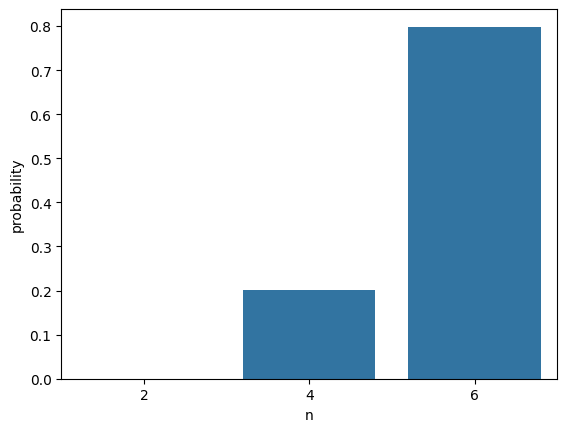

In [49]:
N = 6
temperature = 600  # Kelvin
pressure = 50  # bar
steps = 1e4
time = 1
diffusion = False  # Set to False to disable diffusion

c2_model = joblib.load('../data/adsorption/pt_poly_model.pkl')

C2_conc, C2_out_conc = c2_model.predict_absolute(np.array([pressure * 101325]), 
                                                 np.array([temperature])), \
                    c2_model.predict_out(np.array([pressure * 101325]), 
                                         np.array([temperature]))

energy_barriers = EnergyBarriersSimplifyed(
    temperature=temperature,
    pressure=pressure
)

reactor = ReactorSimulationChemisorptionSimplified(
    N=N,
    T=temperature,
    pressure=pressure,
    L=1000,
    time_hours=time,
    n_steps=int(steps),
    diff_model_path='../data/processed/diffusion_extrap_place_holder_model.pkl',
    ads_model_path='../data/processed/knn_adsorption_slope_model.pkl',
    energy_model=energy_barriers,
    initial_concs={'CatC2(C2)': 1e-2, 'C2': C2_conc[0], 'C2_out': C2_out_conc[0]},
    include_diffusion=diffusion
)


reactor.solver = reactor._build_solver()

def max_constant(reactions):
    return np.max([i[1:] for i in reactions])

def normilize_constants(reactions, r_max=1e6):
    factor = r_max/max_constant(reactions)
    if factor >=1:
        factor = 1
    for i in range(len(reactions)):
        reactions[i] = (reactions[i][0], reactions[i][1] * factor, reactions[i][2] * factor)
    return factor

def remove_back_ins(reactions, N):
    number_of_insertions = N//2 - 2
    for cnt, i in enumerate(reactions):
        if cnt > number_of_insertions:
            break
        reactions[cnt] = (i[0].replace('<->', '->'), i[1], i[2])

def slowdawn_back_ins(reactions, N, order):
    number_of_insertions = N//2 - 2
    for cnt, i in enumerate(reactions):
        if cnt > number_of_insertions:
            break
        reactions[cnt] = (i[0], i[1], i[2]*10**(-order))

def check_errors(ts):
    return all(ts.min() > -1e-2)

factor = normilize_constants(reactor._reactions, r_max=1e6)
remove_back_ins(reactor._reactions, reactor.N)
# slowdawn_back_ins(reactor._reactions, reactor.N, order=8)
reactor.time_hours /= factor

for i in reactor._reactions:
    print('{:35s} {:5.2e} {:5.2e}'.format(*i))

distr, ts = reactor.run(build_solver=False)

sns.barplot(data=distr, x='n', y='probability')
check_convergance(ts, error_threshold=1e-6)
np.round(np.sum(distr.n * distr.probability))

<Axes: >

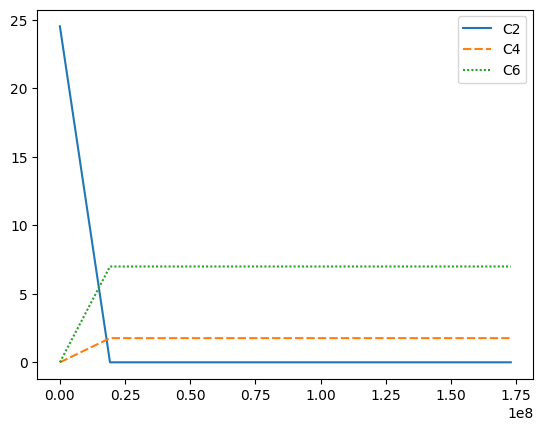

In [51]:
sns.lineplot(ts[::1000])

## Generate data

In [8]:
import os
import tqdm
import warnings
from IPython.display import clear_output
from func_timeout import func_timeout, FunctionTimedOut
from itertools import product
from joblib import Parallel, delayed
from tqdm_joblib import tqdm_joblib
from joblib import Parallel, delayed
from tqdm.auto import tqdm
import numpy as np
import os


c2_model = joblib.load('../data/adsorption/pt_poly_model.pkl')

def get_distr(N, temperature, pressure, steps, time, diffusion, stream, ps, cat_conc, is_remove_back_ins=True):
    C2_conc, C2_out_conc = c2_model.predict_absolute(np.array([pressure * 101325]), 
                                                 np.array([temperature])), \
                    c2_model.predict_out(np.array([pressure * 101325]), 
                                         np.array([temperature]))


    energy_barriers = EnergyBarriersSimplifyed(
        temperature=temperature,
        pressure=pressure
    )

    reactor_model = ReactorStream if stream else ReactorSimulationChemisorptionSimplified
    reactor = reactor_model(
        N=N,
        T=temperature,
        pressure=pressure,
        L=ps,
        time_hours=time,
        n_steps=int(steps),
        diff_model_path='../data/processed/diffusion_extrap_place_holder_model.pkl',
        ads_model_path='../data/processed/knn_adsorption_slope_model.pkl',
        energy_model=energy_barriers,
        initial_concs={'CatC2(C2)': cat_conc, 'C2': C2_conc[0], 'C2_out': C2_out_conc[0]},
        include_diffusion=diffusion
    )
    
    reactor.solver = reactor._build_solver()
    norm_factor = normilize_constants(reactor._reactions, r_max=1e6)
    reactor.time_hours /= norm_factor
    if is_remove_back_ins:
        remove_back_ins(reactor._reactions, reactor.N)
    distr, ts = reactor.run(build_solver=False)
    ts.index = ts.index * norm_factor
    return distr, ts

# --- helper that runs INSIDE the timed worker and captures warnings there ---
def _get_distr_capture_warnings(args_tuple):
    import warnings
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always", category=Warning)
        distr, ts = get_distr(*args_tuple)  # must return (distr, ts)
    had_warnings = any(issubclass(msg.category, Warning) for msg in w)
    return distr, ts, had_warnings

N = 24
df = pd.DataFrame()
steps = 1e3
time = 1e2
temperatures = np.linspace(300, 600, 11)
pressures = np.linspace(1, 50, 3)

diffusion_modes = (True, False)
stream_modes = (True, False)
particle_sizes = (100, 1000)
cat_concentration = (1e-2,)
waiting_time = 30  # seconds
output_folder = 'files/modeling_back_250925_noback/'
is_remove_back_ins = True
# --- Build task list (skip those already on disk) ---
def make_tail(temperature, pressure, N, diffusion, stream, ps, cat_conc):
    return f"temperature_{temperature}_pressure_{pressure}_N_{N}_diffusion_{diffusion}_stream_{stream}_particleSize_{ps}_cat_conc_{cat_conc}"

all_tasks = []
for temperature, ps, pressure, diffusion, stream, cat_conc in product(
        temperatures, particle_sizes, pressures, diffusion_modes, stream_modes, cat_concentration):
    if (not diffusion) and stream:
        continue
    tail = make_tail(temperature, pressure, N, diffusion, stream, ps, cat_conc)
    out_d = f"{output_folder}/distr_{tail}.pkl"
    out_t = f"{output_folder}/ts_{tail}.pkl"
    if os.path.exists(out_d):
        continue
    all_tasks.append((temperature, ps, pressure, diffusion, stream, cat_conc, is_remove_back_ins, tail))

print(f"Queued {len(all_tasks)} tasks")





# --- Worker: identical logic to your serial loop for one (T,ps,p,diff,stream,cat) ---
def run_one_task(task):
    temperature, ps, pressure, diffusion, stream, cat_conc, is_remove_back_ins, tail = task
    try:
        ok = False
        for time_increase in range(1):
            
            try:
                # grow total simulation time geometrically
                ttry = time * (10 ** time_increase)

                distr, ts, had_warnings = func_timeout(
                    waiting_time,
                    _get_distr_capture_warnings,
                    args=((N, temperature, pressure, steps, ttry, diffusion, stream, ps, cat_conc, is_remove_back_ins),)
                )

                had_warnings = not check_errors(ts)
                # any warning -> try longer ttry
                if had_warnings:
                     return {"tail": tail, "status": "skipped_errors"}
                # accept only if converged and warning-free
                if True:#check_convergance(ts, error_threshold=1e6):
                    ok = True
                    break
            except FunctionTimedOut:
                # ran longer than waiting_time -> try next (longer ttry)
                continue
            except Exception:
                # any error -> try next attempt
                continue

        if not ok:
            return {"tail": tail, "status": "skipped_no_convergence"}

        # write outputs (unique filenames -> safe in parallel)
        os.makedirs(output_folder, exist_ok=True)
        distr.to_pickle(f"{output_folder}/distr_{tail}.pkl")
        ts.to_pickle(f"{output_folder}/ts_{tail}.pkl")
        return {"tail": tail, "status": "ok"}

    except Exception as e:
        return {"tail": tail, "status": "error", "error": str(e)}


run_one_task(all_tasks[0])

Queued 198 tasks


{'tail': 'temperature_300.0_pressure_1.0_N_24_diffusion_True_stream_True_particleSize_100_cat_conc_0.01',
 'status': 'ok'}

In [9]:
file = output_folder + 'ts_' + all_tasks[0][-1] + '.pkl'
df = pd.read_pickle(file)
np.all(df >= -1e-8)

np.True_

In [10]:
with tqdm_joblib(tqdm(total=len(all_tasks), desc="Simulating conditions")) as progress_bar:
    results = Parallel(n_jobs=-1, backend="loky", pre_dispatch="2*n_jobs")(
        delayed(run_one_task)(t) for t in all_tasks
    )


# (optional) quick summary
ok_cnt  = sum(r["status"]=="ok" for r in results)
skp_cnt = sum(r["status"]=="skipped_no_convergence" for r in results)
err_cnt = sum(r["status"]=="error" for r in results)
print(f"Done. ok={ok_cnt}, skipped={skp_cnt}, errors={err_cnt}")

Simulating conditions:   0%|          | 0/198 [00:00<?, ?it/s]

  0%|          | 0/198 [00:00<?, ?it/s]

Done. ok=182, skipped=16, errors=0


### Old version

In [8]:
cnt = 0
with tqdm.tqdm(total=len(temperatures) * len(pressures) * len(particle_sizes) * len(cat_concentration) * 3, 
               desc='Simulating conditions') as pbar:
    for temperature in temperatures:
        for ps in particle_sizes:
            for pressure in pressures:
                for diffusion in diffusion_modes:
                    for stream in stream_modes:
                        for cat_conc in cat_concentration:
                            if not diffusion and stream:
                                continue

                            tail = f'temperature_{temperature}_pressure_{pressure}_N_{N}_diffusion_{diffusion}_stream_{stream}_particleSize_{ps}_cat_conc_{cat_conc}'
                            if os.path.exists(f'{output_folder}/distr_{tail}.pkl'):
                                pbar.update(1)
                                continue
                            
                            ok = False

                            for time_increase in range(4):  # try more if you like
                                try:
                                    with warnings.catch_warnings(record=True) as w:
                                        warnings.simplefilter("always", category=Warning)

                                        # grow total simulation time geometrically
                                        ttry = time * (10 ** time_increase)
                                        distr, ts, had_warnings = func_timeout(
                                            waiting_time,
                                            _get_distr_capture_warnings,
                                            args=((N, temperature, pressure, steps, ttry, diffusion, stream, ps, cat_conc),)
                                        )

                                    # if any warning happened, try again with longer time
                                    if had_warnings:
                                        continue

                                    # accept only if converged and warning-free
                                    if check_convergance(ts, error_threshold=1e-4):
                                        ok = True
                                        break
                                except FunctionTimedOut:
                                    # ran longer than waiting_time -> try next (longer ttry) attempt
                                    continue
                                except Exception:
                                    # any error -> just try next (longer) time
                                    continue

                            if not ok:
                                print(f"[warn] Skipped: T={temperature}, p={pressure}, diff={diffusion}, stream={stream} (no clean convergence)")
                                pbar.update(1)
                                continue  # go to next condition in your outer loop

                            distr.to_pickle(f'{output_folder}/distr_{tail}.pkl')
                            ts.to_pickle(f'{output_folder}/ts_{tail}.pkl')
                            pbar.update(1)
                            # Clear IPython output every 10 iterations to prevent memory buildup
                            cnt += 1
                            if cnt % 5 == 0:
                                clear_output(wait=True)






Simulating conditions: 100%|██████████| 60/60 [04:35<00:00,  4.59s/it]


# Analyse data

In [1]:
import glob
import os
import pandas as pd
import re
import numpy as np


def time_distribution(result: pd.DataFrame) -> pd.DataFrame:
    """
    Compute per-time distribution P(C_n | n>2) from a wide time series.

    Input
    -----
    result : DataFrame with columns like:
        time, C2, C2_out, C4, C4_out, C6, C6_out, ...

    Output
    ------
    DataFrame with columns:
        time, n, probability   (only n > 2)

    Notes
    -----
    - Uses only in-reactor columns matching exactly 'C\\d+' (excludes '*_out').
    - If total concentration of n>2 at a time is 0, probabilities are NaN for that time.
    """
    if 'time' not in result.columns:
        raise ValueError("Input must contain a 'time' column.")

    # Keep only exact Cn columns (exclude *_out etc.)
    cn_cols = [c for c in result.columns if re.fullmatch(r'C\d+', c)]

    if not cn_cols:
        return pd.DataFrame(columns=['time', 'n', 'probability'])

    # Wide -> long
    long = (result[['time'] + cn_cols]
            .melt(id_vars='time', var_name='species', value_name='concentration'))

    # Extract n
    long['n'] = long['species'].str.extract(r'(\d+)').astype(int)

    # Totals per time over n>2
    totals = (long.loc[long['n'] > 2]
                    .groupby('time', as_index=False)['concentration']
                    .sum()
                    .rename(columns={'concentration': 'total_conc'}))

    # Merge totals, compute probabilities, filter n>2
    out = (long.merge(totals, on='time', how='left')
                .assign(probability=lambda d: d['concentration'] / d['total_conc'])
                .loc[lambda d: d['n'] > 2, ['time', 'n', 'probability']]
                .sort_values(['time', 'n'])
                .reset_index(drop=True))

    return out


def tail_slope_prob_per_n(dist: pd.DataFrame, tail_frac: float = 0.10) -> pd.DataFrame:
    """
    Compute d(probability)/dt for each n over the last `tail_frac` of the simulation time.

    Parameters
    ----------
    dist : pd.DataFrame
        Long-form dataframe with columns: ['time', 'n', 'probability'].
    tail_frac : float, optional (default=0.10)
        Fraction of the *time span* to use from the end (e.g., 0.10 = last 10%).

    Returns
    -------
    pd.DataFrame with columns:
        - n : int
        - slope : float  (units: probability per time)
        - window_start : float  (time at which the tail window starts)
        - window_end : float    (max time)
        - points_used : int     (# of points used in the fit for that n)

    Notes
    -----
    - Uses np.polyfit on (time, probability) within the tail window, after dropping NaNs.
    - If fewer than 2 points for an n in the tail window, slope is NaN.
    """
    required_cols = {'time', 'n', 'probability'}
    missing = required_cols - set(dist.columns)
    if missing:
        raise ValueError(f"Input distribution is missing columns: {missing}")

    # Ensure proper dtypes
    d = dist[['time', 'n', 'probability']].copy()
    d['time'] = pd.to_numeric(d['time'], errors='coerce')
    d['n'] = pd.to_numeric(d['n'], errors='coerce', downcast='integer')
    d['probability'] = pd.to_numeric(d['probability'], errors='coerce')

    # Determine tail time window using the overall time span
    t_min = d['time'].min()
    t_max = d['time'].max()
    if not np.isfinite(t_min) or not np.isfinite(t_max):
        return pd.DataFrame(columns=['n', 'slope', 'window_start', 'window_end', 'points_used'])

    window_start = t_min + (1 - tail_frac) * (t_max - t_min)
    tail = d[(d['time'] >= window_start) & (d['time'] <= t_max)]

    results = []
    for n_val, g in tail.groupby('n', dropna=True):
        g = g.dropna(subset=['time', 'probability']).sort_values('time')
        if len(g) < 2:
            slope = np.nan
            points_used = len(g)
        else:
            # Linear fit: probability ~ a*time + b; slope = a
            a, b = np.polyfit(g['time'].values, g['probability'].values, deg=1)
            slope = float(a)
            points_used = len(g)

        results.append({
            'n': int(n_val) if pd.notna(n_val) else np.nan,
            'slope': slope,
            'window_start': float(window_start),
            'window_end': float(t_max),
            'points_used': int(points_used),
        })

    return pd.DataFrame(results).sort_values('n').reset_index(drop=True)


def get_tail_distribution(file, error_threshold=1e-2):
    df = pd.read_pickle(file)
    distr = time_distribution(df.reset_index(names=['time']))
    is_converged = bool(tail_slope_prob_per_n(distr, tail_frac=0.10).slope.abs().max() < error_threshold)
    if is_converged:
        return distr[distr.time == distr.time.max()]
    return None

In [2]:
# Initialize empty dataframe
df = pd.DataFrame()

# Get all distribution files
files = glob.glob('files/reactor_modeling/ts_temperature_*_pressure_*_N_*_diffusion_*_stream_*_particleSize_*_cat_conc_*.pkl')

failed_runs = []

for file in files:
    # Extract parameters from filename
    params = file.split('_')
    temperature = float(params[params.index('temperature')+1])
    if temperature > 350:
        continue
    pressure = float(params[params.index('pressure')+1])
    N = int(params[params.index('N')+1])
    diffusion = params[params.index('diffusion')+1] == 'True'
    stream = params[params.index('stream')+1] == 'True'
    ps = int(params[params.index('particleSize')+1])
    cat_conc = float(params[params.index('conc')+1].split('.')[0])
    # Read distribution file
    distr = get_tail_distribution(file, error_threshold=5e-2)
    if distr is None:
        failed_runs.append(file)
        print(f"Skipping non-converged run: {file}")
        continue    
    # Add parameters as columns
    distr['temperature'] = temperature
    distr['pressure'] = pressure
    distr['N'] = N
    distr['diffusion'] = diffusion
    distr['is_stream'] = stream
    distr['particle_size'] = ps
    distr['cat_conc'] = cat_conc
    
    # Append to main dataframe
    df = pd.concat([df, distr], ignore_index=True)
    break

df

,time,n,probability,temperature,pressure,N,diffusion,is_stream,particle_size,cat_conc
0,36.0,4,0.269299,300.0,1.0,16,True,True,20,0.0
1,36.0,6,0.605542,300.0,1.0,16,True,True,20,0.0
2,36.0,8,0.107644,300.0,1.0,16,True,True,20,0.0
3,36.0,10,0.015390,300.0,1.0,16,True,True,20,0.0
4,36.0,12,0.001893,300.0,1.0,16,True,True,20,0.0
5,36.0,14,0.000208,300.0,1.0,16,True,True,20,0.0
6,36.0,16,0.000023,300.0,1.0,16,True,True,20,0.0


In [ ]:
df = df[(df.N == 16) & (df.temperature <= 470)]

In [ ]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(8, 3))

temperature = 470
dft = df.query(f'temperature=={temperature} and not is_stream and n > 2 and diffusion')
sns.barplot(data=dft, x='n', y='probability', hue='pressure', ax=axs[0])

dft = df.query(f'temperature=={temperature} and is_stream and n > 2')
sns.barplot(data=dft, x='n', y='probability', hue='pressure', ax=axs[1])


In [ ]:
def mass(n):
    M = 12 * n + 2 * n
    return M

df = df[df.n != 2].copy()
df['mass'] = mass(df.n)
df['expected_mass'] = df.probability * df.mass
df = df.groupby(['temperature', 'pressure', 'is_stream', 'diffusion']).agg({
    'expected_mass': 'sum'
}).reset_index()

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(8, 4), dpi=200)

sns.lineplot(data=df[df.diffusion & (~df.is_stream)],
             y='expected_mass',
             x='temperature',
             hue='pressure',
             palette='viridis',
             ax=axs[0])

sns.lineplot(data=df[df.diffusion & df.is_stream],
             y='expected_mass',
             x='temperature',
             hue='pressure',
             palette='viridis',
             ax=axs[1])

axs[0].set_title('Batch mode')
axs[1].set_title('Flow mode')

handles, labels = axs[0].get_legend_handles_labels()
for cnt in range(2):
    axs[cnt].legend_.remove()
    box = axs[cnt].get_position()
    axs[cnt].set_position([box.x0, box.y0, box.width*1.1, box.height])
    axs[cnt].set_ylim(85, 180)

axs[1].set_ylabel('')
axs[1].set_yticklabels([])
    
labels = ['Pressure (bar)'] + labels[1:]
fig.legend(handles, labels, bbox_to_anchor=[1.12, 0.9], frameon=False)

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(8, 4), dpi=200)

sns.lineplot(data=df[(~df.diffusion) & (~df.is_stream)],
             y='expected_mass',
             x='temperature',
             hue='pressure',
             palette='viridis',
             ax=axs[0])

sns.lineplot(data=df[df.is_stream],
             y='expected_mass',
             x='temperature',
             hue='pressure',
             palette='viridis',
             ax=axs[1])

axs[0].set_title('Batch mode no diffusion')
axs[1].set_title('Batch mode diffusion')

handles, labels = axs[0].get_legend_handles_labels()
for cnt in range(2):
    axs[cnt].legend_.remove()
    box = axs[cnt].get_position()
    axs[cnt].set_position([box.x0, box.y0, box.width*1.1, box.height])
    axs[cnt].set_ylim(85, 240)

axs[1].set_ylabel('')
axs[1].set_yticklabels([])
    
labels = ['Pressure (bar)'] + labels[1:]
fig.legend(handles, labels, bbox_to_anchor=[1.12, 0.9], frameon=False)

# Convergance

## Timestep

In [ ]:
c2_model = joblib.load('../data/adsorption/pt_poly_model.pkl')

def test_reactor(N=10, temperature=600, pressure=1, steps=1e4, time=1, diffusion=True):
    C2_conc, C2_out_conc = c2_model.predict_absolute(np.array([pressure * 101325]), 
                                                    np.array([temperature])), \
                        c2_model.predict_out(np.array([pressure * 101325]), 
                                            np.array([temperature]))


    energy_barriers = EnergyBarriersSimplifyed(
        temperature=temperature,
        pressure=pressure
    )


    reactor = ReactorSimulationChemisorptionSimplified(
        N=N,
        T=temperature,
        pressure=pressure,
        L=20,
        time_hours=time,
        n_steps=int(steps),
        diff_model_path='../data/processed/diffusion_extrap_place_holder_model.pkl',
        ads_model_path='../data/processed/knn_adsorption_slope_model.pkl',
        energy_model=energy_barriers,
        initial_concs={'CatC2(C2)': 1e-2, 'C2': C2_conc[0], 'C2_out': C2_out_conc[0]},
        include_diffusion=diffusion
    )

    return reactor.run()


distr, ts = test_reactor(N = 10,
temperature = 600,  # Kelvin
pressure = 1,  # bar
steps = 1e4,
time = 1e-5,
diffusion = True)

ts = ts.reset_index(names=['time'])

sns.lineplot(data=ts.melt(id_vars=['time'], value_vars=['C4', 'C6', 'C8']), 
            x='time', 
            y='value',
            hue='variable',
            palette='viridis')
distr

In [ ]:
def calc_dt(time, n_steps):
    return time/n_steps

n_steps = 1e1
time = 0.01/3600
print('dt = {:5.2e}'.format(calc_dt(time, n_steps)))
distr0, ts0 = test_reactor(steps=n_steps, time=time)

n_steps = 1e6
time = 0.01/3600
print('dt = {:5.2e}'.format(calc_dt(time, n_steps)))
distr1, ts1 = test_reactor(steps=n_steps, time=time)

distr0.dropna() - distr1.dropna()

In [ ]:
def calc_n_steps(dt, time):
    return time/dt

def compare_reactions(dt0, dt1, time):
    n_steps = calc_n_steps(dt0, time)
    distr0, ts0 = test_reactor(steps=n_steps, time=time)

    n_steps = calc_n_steps(dt1, time)
    distr1, ts1 = test_reactor(steps=n_steps, time=time)

    return distr0, ts0, distr1, ts1

distr0, ts0, distr1, ts1 = compare_reactions(1e-12, 1e-7, 1e-6)
(distr0 - distr1).dropna().sum()

distr0, ts0, distr1, ts1 = compare_reactions(1e-7, 1e-2, 1e-1)
(distr0 - distr1).dropna().sum()

# distr0, ts0, distr1, ts1 = compare_reactions(1e-2, 1e2, 1e3)
# (distr0 - distr1).dropna().sum()

## Distribution convergance

In [ ]:
c2_model = joblib.load('../data/adsorption/pt_poly_model.pkl')

def test_reactor(N=10, temperature=300, pressure=1, steps=1e4, time=1, diffusion=True):
    C2_conc, C2_out_conc = c2_model.predict_absolute(np.array([pressure * 101325]), 
                                                    np.array([temperature])), \
                        c2_model.predict_out(np.array([pressure * 101325]), 
                                            np.array([temperature]))


    energy_barriers = EnergyBarriersSimplifyed(
        temperature=temperature,
        pressure=pressure
    )


    reactor = ReactorSimulationChemisorptionSimplified(
        N=N,
        T=temperature,
        pressure=pressure,
        L=20,
        time_hours=time,
        n_steps=int(steps),
        diff_model_path='../data/processed/diffusion_extrap_place_holder_model.pkl',
        ads_model_path='../data/processed/knn_adsorption_slope_model.pkl',
        energy_model=energy_barriers,
        initial_concs={'CatC2(C2)': 1e-2, 'C2': C2_conc[0], 'C2_out': C2_out_conc[0]},
        include_diffusion=diffusion
    )

    return reactor.run()


distr, ts = test_reactor(N = 10,
temperature = 600,  # Kelvin
pressure = 1,  # bar
steps = 1e4,
time = 1e-5,
diffusion = True)

ts = ts.reset_index(names=['time'])

sns.lineplot(data=ts.melt(id_vars=['time'], value_vars=['C4', 'C6', 'C8']), 
            x='time', 
            y='value',
            hue='variable',
            palette='viridis')


In [ ]:
import re
import tqdm

def time_distribution(result: pd.DataFrame) -> pd.DataFrame:
    """
    Compute per-time distribution P(C_n | n>2) from a wide time series.

    Input
    -----
    result : DataFrame with columns like:
        time, C2, C2_out, C4, C4_out, C6, C6_out, ...

    Output
    ------
    DataFrame with columns:
        time, n, probability   (only n > 2)

    Notes
    -----
    - Uses only in-reactor columns matching exactly 'C\\d+' (excludes '*_out').
    - If total concentration of n>2 at a time is 0, probabilities are NaN for that time.
    """
    if 'time' not in result.columns:
        raise ValueError("Input must contain a 'time' column.")

    # Keep only exact Cn columns (exclude *_out etc.)
    cn_cols = [c for c in result.columns if re.fullmatch(r'C\d+', c)]

    if not cn_cols:
        return pd.DataFrame(columns=['time', 'n', 'probability'])

    # Wide -> long
    long = (result[['time'] + cn_cols]
            .melt(id_vars='time', var_name='species', value_name='concentration'))

    # Extract n
    long['n'] = long['species'].str.extract(r'(\d+)').astype(int)

    # Totals per time over n>2
    totals = (long.loc[long['n'] > 2]
                    .groupby('time', as_index=False)['concentration']
                    .sum()
                    .rename(columns={'concentration': 'total_conc'}))

    # Merge totals, compute probabilities, filter n>2
    out = (long.merge(totals, on='time', how='left')
                .assign(probability=lambda d: d['concentration'] / d['total_conc'])
                .loc[lambda d: d['n'] > 2, ['time', 'n', 'probability']]
                .sort_values(['time', 'n'])
                .reset_index(drop=True))

    return out


pressures = np.linspace(1, 50, 5)
temperatures = np.linspace(300, 350, 2)

df = pd.DataFrame()
with tqdm.tqdm(total=len(pressures) * len(temperatures), desc="Testing conditions") as pbar:
    for temperature in temperatures:
        for pressure in pressures:
            distr, ts = test_reactor(N = 10,
            temperature = temperature,  # Kelvin
            pressure = pressure,  # bar
            steps = 1e3,
            time = 1e-2,
            diffusion = True)

            td = time_distribution(ts.reset_index(names=['time']))
            td['temperature'] = temperature
            td['pressure'] = pressure
            df = pd.concat([df, td])
            pbar.update(1)
            
df = df.dropna()

In [ ]:
def tail_slope_prob_per_n(dist: pd.DataFrame, tail_frac: float = 0.10) -> pd.DataFrame:
    """
    Compute d(probability)/dt for each n over the last `tail_frac` of the simulation time.

    Parameters
    ----------
    dist : pd.DataFrame
        Long-form dataframe with columns: ['time', 'n', 'probability'].
    tail_frac : float, optional (default=0.10)
        Fraction of the *time span* to use from the end (e.g., 0.10 = last 10%).

    Returns
    -------
    pd.DataFrame with columns:
        - n : int
        - slope : float  (units: probability per time)
        - window_start : float  (time at which the tail window starts)
        - window_end : float    (max time)
        - points_used : int     (# of points used in the fit for that n)

    Notes
    -----
    - Uses np.polyfit on (time, probability) within the tail window, after dropping NaNs.
    - If fewer than 2 points for an n in the tail window, slope is NaN.
    """
    required_cols = {'time', 'n', 'probability'}
    missing = required_cols - set(dist.columns)
    if missing:
        raise ValueError(f"Input distribution is missing columns: {missing}")

    # Ensure proper dtypes
    d = dist[['time', 'n', 'probability']].copy()
    d['time'] = pd.to_numeric(d['time'], errors='coerce')
    d['n'] = pd.to_numeric(d['n'], errors='coerce', downcast='integer')
    d['probability'] = pd.to_numeric(d['probability'], errors='coerce')

    # Determine tail time window using the overall time span
    t_min = d['time'].min()
    t_max = d['time'].max()
    if not np.isfinite(t_min) or not np.isfinite(t_max):
        return pd.DataFrame(columns=['n', 'slope', 'window_start', 'window_end', 'points_used'])

    window_start = t_min + (1 - tail_frac) * (t_max - t_min)
    tail = d[(d['time'] >= window_start) & (d['time'] <= t_max)]

    results = []
    for n_val, g in tail.groupby('n', dropna=True):
        g = g.dropna(subset=['time', 'probability']).sort_values('time')
        if len(g) < 2:
            slope = np.nan
            points_used = len(g)
        else:
            # Linear fit: probability ~ a*time + b; slope = a
            a, b = np.polyfit(g['time'].values, g['probability'].values, deg=1)
            slope = float(a)
            points_used = len(g)

        results.append({
            'n': int(n_val) if pd.notna(n_val) else np.nan,
            'slope': slope,
            'window_start': float(window_start),
            'window_end': float(t_max),
            'points_used': int(points_used),
        })

    return pd.DataFrame(results).sort_values('n').reset_index(drop=True)



# Create empty dataframe to store results
results = []

# For each unique combination of temperature and pressure
for temp, pres in df[['temperature', 'pressure']].drop_duplicates().values:
    # Get slope data for this condition
    slopes = tail_slope_prob_per_n(df.query('temperature == @temp and pressure == @pres'))
    # Add temperature and pressure columns
    slopes['temperature'] = temp
    slopes['pressure'] = pres
    results.append(slopes)

# Combine all results
final_df = pd.concat(results, ignore_index=True)

In [ ]:
import glob
files = glob.glob('files/ts_temperature_*_pressure_*_N_*_diffusion_*_stream_*.pkl')
df = pd.DataFrame()
for file in tqdm.tqdm(files):
    # Extract parameters from filename
    params = file.split('_')
    temperature = float(params[params.index('temperature')+1])
    pressure = float(params[params.index('pressure')+1])
    N = int(params[params.index('N')+1])
    diffusion = params[params.index('diffusion')+1] == 'True'
    stream = params[params.index('stream')+1].split('.')[0] == 'True'
    td = time_distribution(pd.read_pickle(file).reset_index(names=['time']))
    slope = tail_slope_prob_per_n(td)
    slope['temperature'] = temperature
    slope['pressure'] = pressure
    slope['N'] = N
    slope['diffusion'] = diffusion
    slope['stream'] = stream
    df = pd.concat([df, slope])




# Tests

In [ ]:
import matplotlib.pyplot as plt


class ReactorTest(ReactorSimulationChemisorptionSimplified):
    """
    A class to handle the reactor stream simulation.
    Inherits from ReactorSimulationChemisorption.
    """
    def __init__(self, delta_ins=1, delta_deins=1, delta_elim=1, delta_deelim=1, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.delta_ins = delta_ins
        self.delta_deins = delta_deins
        self.delta_elim = delta_elim
        self.delta_deelim = delta_deelim

    def _build_solver(self):
        df, idx = self._make_dataframe()
        self._diffusion_rates = self._calc_diffusion_constants(df, idx)
        self._capacity = self._calc_capacity(df, idx)

        self.consts = prepare_constants_chemisorp_simplified(
            self.barrier_params,
            temperature=self.T
        )

        self.consts['k_insertion_di'] *= self.delta_ins
        self.consts['k_insertion_tri'] *= self.delta_ins
        self.consts['k_insertion_tetra'] *= self.delta_ins

        self.consts['k_deinsertion_di'] *= self.delta_deins
        self.consts['k_deinsertion_tri'] *= self.delta_deins
        self.consts['k_deinsertion_tetra'] *= self.delta_deins

        self.consts['k_elimination_di'] *= self.delta_elim
        self.consts['k_elimination_tri'] *= self.delta_elim
        self.consts['k_elimination_tetra'] *= self.delta_elim

        self.consts['k_deelimination_di'] *= self.delta_deelim
        self.consts['k_deelimination_tri'] *= self.delta_deelim
        self.consts['k_deelimination_tetra'] *= self.delta_deelim
        
        self._reactions = make_reaction_list_chemisorp_simplified(
            n_max=self.N,
            consts=self.consts,
            diffusion_rates=self._diffusion_rates,
            include_diffusion=self.include_diffusion

        )
        return Reaction_Diffusion(reactions=self._reactions, capacity=self._capacity)
    

N = 16
temperature = 300  # Kelvin
pressure = 1  # bar
steps = 1e6
time = 1e1
diffusion = True  # Set to False to disable diffusion



reactor = ReactorTest(
    N=N,
    T=temperature,
    pressure=pressure,
    L=20,
    time_hours=time,
    n_steps=int(steps),
    diff_model_path='../data/processed/diffusion_extrap_place_holder_model.pkl',
    ads_model_path='../data/processed/knn_adsorption_slope_model.pkl',
    energy_model=energy_barriers,
    initial_concs={'CatC2(C2)': 1e-2, 'C2': C2_conc[0], 'C2_out': C2_out_conc[0]},
    include_diffusion=diffusion,
)

distr, ts = reactor.run()
ts = ts.loc[::1000, :].copy()
for i in reactor._reactions:
    print('{:36s} {:5.3e} {:5.3e}'.format(*i))

for i in range(2, N+1, 2):
    ts.loc[:, f'C{i}'] += ts[f'C{i}_out'].values

ts = ts.reset_index(names=['time'])
ts = ts.drop(columns=([f'C{i}_out' for i in range(2, N+1, 2)]))
fig, axs = plt.subplots(1, 2, figsize=(12, 5), dpi=200)
sns.barplot(data=distr, x='n', y='probability', ax=axs[0])
sns.lineplot(data=ts.melt(id_vars=['time'], value_vars=[f'C{n}' for n in range(2, N+1, 2)]), 
            x='time', 
            y='value',
            hue='variable',
            ax=axs[1])

distr

In [ ]:
import tqdm

def run_reactor(delta_ins=1, delta_deins=1, delta_elim=1, delta_deelim=1, temperature=300, pressure=1, time=1e1):
    N = 16
    steps = 1e5
    diffusion = True  # Set to False to disable diffusion

    reactor = ReactorTest(
        N=N,
        T=temperature,
        pressure=pressure,
        L=20,
        time_hours=time,
        n_steps=int(steps),
        diff_model_path='../data/processed/diffusion_extrap_place_holder_model.pkl',
        ads_model_path='../data/processed/knn_adsorption_slope_model.pkl',
        energy_model=energy_barriers,
        initial_concs={'CatC2(C2)': 1e-2, 'C2': C2_conc[0], 'C2_out': C2_out_conc[0]},
        include_diffusion=diffusion,
        delta_ins=delta_ins, delta_deins=delta_deins, delta_elim=delta_elim, delta_deelim=delta_deelim
    )

    distr, _ = reactor.run()
    if np.abs(distr.iloc[0, 1]) > 1e-3:
        raise ValueError('Distr is not converged')
    return distr

def mass(n):
    return 14*n

def expected_mass(distr):
    distr['expected_mass'] = distr.n.apply(mass) * distr.probability
    expected_mass = distr.expected_mass.sum()
    return expected_mass


def get_derivetive(k=1.1, base='10', temperature=300, pressure=1, time=1e1):
    """
    Central finite difference of dM/dlog(param), varying each delta_* multiplicatively by k and 1/k.
    Returns a dict with keys: 'ins', 'deins', 'elim', 'deelim'.
    """
    if k <= 1.0:
        raise ValueError("k must be > 1 for a multiplicative step.")

    params = ['delta_ins', 'delta_deins', 'delta_elim', 'delta_deelim']
    keys   = ['ins',       'deins',        'elim',        'deelim']
    derivatives = {}

    # choose log base
    log = np.log10 if base == '10' else np.log
    denom = 2.0 * log(k)

    for param, key in zip(params, keys):
        # baseline args: all 1.0
        args_plus  = dict(delta_ins=1.0, delta_deins=1.0, delta_elim=1.0, delta_deelim=1.0)
        args_minus = dict(args_plus)
        args_plus[param]  = k
        args_minus[param] = 1.0 / k

        M_plus  = expected_mass(run_reactor(**args_plus,  temperature=temperature, pressure=pressure, time=time))
        M_minus = expected_mass(run_reactor(**args_minus, temperature=temperature, pressure=pressure, time=time))

        derivatives[key] = (M_plus - M_minus) / denom

    return derivatives


time = 1e1
df = pd.DataFrame()
with tqdm.tqdm(total=5*5, desc="Calculating derivatives") as pbar:
    for temperature in np.linspace(300, 420, 5):
        for pressure in np.linspace(1, 50, 5):
            if temperature > 400:
                time = 1e-1
            derivetive = get_derivetive(k=1.2, temperature=temperature, pressure=pressure, time=time)
            pbar.update(1)
            derivetive = pd.DataFrame([derivetive])
            derivetive['temperature'] = temperature
            derivetive['pressure'] = pressure
            df = pd.concat([df, derivetive], ignore_index=True)
df_melt = df.melt(id_vars=['temperature', 'pressure'], var_name='parameter', value_name='sensitivity')

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(12, 6), dpi=200)
sns.lineplot(data=df, x='temperature', y='ins', hue='pressure', marker='o', ax=axs[0, 0])
sns.lineplot(data=df, x='temperature', y='deins', hue='pressure', marker='o', ax=axs[0, 1])
sns.lineplot(data=df, x='temperature', y='elim', hue='pressure', marker='o', ax=axs[1, 0])
sns.lineplot(data=df, x='temperature', y='deelim', hue='pressure', marker='o', ax=axs[1, 1])
axs[0, 0].set_title('Insertion sensitivity')
axs[0, 1].set_title('De-insertion sensitivity')
axs[1, 0].set_title('Elimination sensitivity')
axs[1, 1].set_title('De-elimination sensitivity')

for i in range(2):
    for j in range(2):
        axs[i, j].legend_.remove()
        box = axs[i, j].get_position()
        axs[i, j].set_position([box.x0, box.y0, box.width*1.1, box.height *0.90])
        axs[i, j].axhline(0, color='black', linestyle='--', linewidth=0.8)
        axs[i, j].set_ylabel('dM/dlog(param) (g/mol)')
        axs[0, j].set_xlabel('')

In [ ]:
# --- Paper-ready 2×2 sensitivity grid (global legend, tidy axes) ---
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Helper: nice per-panel y-lims with a bit of padding
def _ylims_from(data, ycol, pad=0.05):
    y = np.asarray(data[ycol].dropna())
    if y.size == 0:
        return None
    ymin, ymax = np.min(y), np.max(y)
    if np.isclose(ymin, ymax):
        delta = 1.0 if ymax == 0 else 0.1 * abs(ymax)
        return (ymin - delta, ymax + delta)
    span = ymax - ymin
    return (ymin - pad * span, ymax + pad * span)

# Common x-limits/ticks from full dataset (shared across panels)
xvals = np.sort(df['temperature'].unique())
xlim = (xvals.min()-10, xvals.max()+10)
xticks = xvals  # explicit ticks at your simulated temperatures

fig, axs = plt.subplots(2, 2, figsize=(7.0, 4.0), dpi=800)

panels = [
    ('ins',    'Insertion sensitivity'),
    ('deins',  'De-insertion sensitivity'),
    ('elim',   'Elimination sensitivity'),
    ('deelim', 'De-elimination sensitivity'),
]

# Draw panels
for ax, (ycol, title) in zip(axs.flatten(), panels):
    sns.lineplot(
        data=df, x='temperature', y=ycol, hue='pressure',
        marker='o', linewidth=1.2, ms=4,
        palette=(color_map if 'color_map' in globals() else None),
        ax=ax
    )
    ax.set_title(title, loc='left', fontsize=10)
    ax.axhline(0, ls='--', lw=0.8, c='k')
    ax.set_xlim(*xlim)
    ax.set_xticks(xticks)
    # Per-panel y-limits
    ylim = _ylims_from(df, ycol)
    if ylim: ax.set_ylim(*ylim)

# Labels (LaTeX style); only bottom row gets x-labels; only left col gets y-ticks/labels
for i in range(2):
    for j in range(2):
        ax = axs[i, j]
        # Legends removed per-axis; global legend added below
        if ax.legend_ is not None:
            ax.legend_.remove()
        # X labels only on bottom row
        ax.set_xlabel(r'$T\ \mathrm{(K)}$' if i == 1 else '')
        # Y labels only on left column
        if j == 0:
            ax.set_ylabel(r'$dM/d\log(\mathrm{k})\ \mathrm{(g\,mol^{-1})}$')
        else:
            ax.set_ylabel('')
            ax.set_yticklabels([])  # hide right-column tick labels

# Compact spacing
for ax in axs[1, :]:
    box = ax.get_position()
    ax.set_position([box.x0, box.y0 - 0.04, box.width, box.height])

# Global legend with pressures
handles, labels = axs[0, 0].get_legend_handles_labels()
# Tidy pressure labels with units
try:
    pressures = [float(lab) for lab in labels]
    labels = [f'{p:g} bar' for p in pressures]
except Exception:
    # If they’re already strings like "1 bar", keep as-is
    pass

fig.legend(
    handles, labels, loc='center left',
    bbox_to_anchor=(0.1, 0.0), frameon=False, title='', ncol=5,
)

fig.tight_layout()
fig.savefig('files/plots/sensitivities_grid.pdf', bbox_inches='tight')
fig.savefig('files/plots/sensitivities_grid.svg', bbox_inches='tight')